In [1]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt

grade = gpd.read_file(
    Path("../dados/processados/centro_brotas_h3_res10_populacao.gpkg"),
    layer="populacao_estimada"
)

unidades = gpd.read_file(
    Path("../dados/processados/ubs_usf_salvador.gpkg"),
    layer="ubs_usf"
)

print("Grade:", len(grade), grade.crs)
print("Unidades:", len(unidades), unidades.crs)

Grade: 1145 EPSG:31984
Unidades: 142 EPSG:31984


In [2]:
pontos_grade = grade.copy()

pontos_grade["geometry"] = (
    grade.geometry.representative_point()
)

In [3]:
print("Pontos:", len(pontos_grade))
print("CRS:", pontos_grade.crs)

print(
    "Pontos dentro da própria célula:",
    pontos_grade.geometry.within(grade.geometry).sum()
)

Pontos: 1145
CRS: EPSG:31984
Pontos dentro da própria célula: 1145


In [4]:
proximidade = gpd.sjoin_nearest(
    pontos_grade[["h3_id", "pop_estimada", "geometry"]],
    unidades[["unidade", "tipo_tratado", "geometry"]],
    how="left",
    distance_col="distancia_m"
)

In [5]:
print("Linhas:", len(proximidade))
print("Células únicas:", proximidade["h3_id"].nunique())
print("Distâncias ausentes:", proximidade["distancia_m"].isna().sum())
print("Ocorrências adicionais por empate:",
      proximidade["h3_id"].duplicated().sum())

print(proximidade["distancia_m"].describe())

Linhas: 1145
Células únicas: 1145
Distâncias ausentes: 0
Ocorrências adicionais por empate: 0
count    1145.000000
mean      562.598494
std       282.774307
min        19.932940
25%       344.989538
50%       537.883905
75%       764.497469
max      1489.892455
Name: distancia_m, dtype: float64


In [6]:
media_ponderada = (
    proximidade["distancia_m"] * proximidade["pop_estimada"]
).sum() / proximidade["pop_estimada"].sum()

print(f"Distância média ponderada: {media_ponderada:.2f} m")

Distância média ponderada: 511.48 m


In [7]:
grade_distancia = grade.merge(
    proximidade[
        ["h3_id", "unidade", "tipo_tratado", "distancia_m"]
    ],
    on="h3_id",
    how="left",
    validate="one_to_one"
)

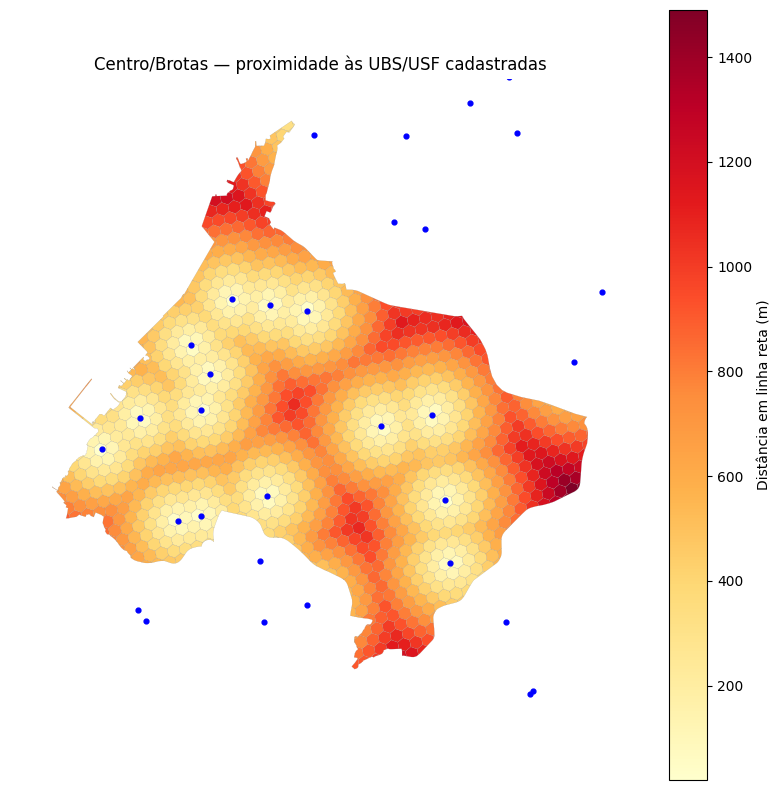

In [8]:
fig, ax = plt.subplots(figsize=(10, 10))

grade_distancia.plot(
    column="distancia_m",
    ax=ax,
    cmap="YlOrRd",
    legend=True,
    edgecolor="gray",
    linewidth=0.1,
    legend_kwds={"label": "Distância em linha reta (m)"}
)

unidades.plot(
    ax=ax,
    color="blue",
    markersize=12
)

# Mantém o mapa concentrado no piloto
xmin, ymin, xmax, ymax = grade_distancia.total_bounds
ax.set_xlim(xmin - 500, xmax + 500)
ax.set_ylim(ymin - 500, ymax + 500)

ax.set_title("Centro/Brotas — proximidade às UBS/USF cadastradas")
ax.set_axis_off()

plt.show()

In [9]:
acima_1km = grade_distancia.loc[
    grade_distancia["distancia_m"] > 1000
]

pop_acima_1km = acima_1km["pop_estimada"].sum()
pop_total = grade_distancia["pop_estimada"].sum()

print("Células acima de 1 km:", len(acima_1km))
print(f"População estimada nessas células: {pop_acima_1km:.2f}")
print(f"Percentual da população estimada: {100 * pop_acima_1km / pop_total:.2f}%")

Células acima de 1 km: 87
População estimada nessas células: 9713.52
Percentual da população estimada: 4.07%


In [10]:
arquivo_proximidade = Path(
    "../dados/processados/centro_brotas_h3_res10_proximidade.gpkg"
)

grade_distancia.to_file(
    arquivo_proximidade,
    layer="proximidade_ubs_usf",
    driver="GPKG",
    index=False
)

In [11]:
conferencia = gpd.read_file(
    arquivo_proximidade,
    layer="proximidade_ubs_usf"
)

print("Células:", len(conferencia))
print("Distâncias ausentes:", conferencia["distancia_m"].isna().sum())
print(f"População estimada: {conferencia['pop_estimada'].sum():.6f}")

Células: 1145
Distâncias ausentes: 0
População estimada: 238643.078117
